# A researcher wants to compare the exam performance of students from two different teaching methods.

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import t,ttest_ind

In [5]:
method_A = [75, 80, 85, 78, 82, 88, 76, 81]
method_B = [68, 72, 70, 75, 69, 74, 71, 73]
df = pd.DataFrame({"Method_A":method_A,"Method_B":method_B})
df


,Method_A,Method_B
0,75,68
1,80,72
2,85,70
3,78,75
4,82,69
5,88,74
6,76,71
7,81,73


In [6]:
sample_mean_of_A = df["Method_A"].mean()
sample_mean_of_B = df["Method_B"].mean()
sample_size = len(df["Method_A"])  + len(df["Method_B"])
alpha = 0.05
DOF = sample_size - 1 
print("Sample mean of method A : ",sample_mean_of_A)
print("sample_mean_of_B : ",sample_mean_of_B)
print("size of the dat frame : ",sample_size)
print("significance level : ",alpha)
print("Degree of freedom : ",DOF)

Sample mean of method A :  80.625
sample_mean_of_B :  71.5
size of the dat frame :  16
significance level :  0.05
Degree of freedom :  15


In [7]:
t_test_stat ,p_value = ttest_ind(df["Method_A"],df["Method_B"],alternative="two-sided")
print("t test stats : ",t_test_stat)
print("p value : ",p_value)

t test stats :  5.119993741211916
p value :  0.00015585294766579062


In [8]:
# critical value 

critical_value = t._ppf(1-alpha/2,DOF)
print("critcal_value : ",critical_value)
lower_fence = -critical_value
upper_fence = critical_value 
print("lower fence : ",lower_fence)
print("upper fence : ",upper_fence)


critcal_value :  2.131449545559776
lower fence :  -2.131449545559776
upper fence :  2.131449545559776


In [9]:
if p_value < alpha :
    print("Decision : we reject the null hypothesis .")
    print("Conclusion : there is sufficient evidence at 5 % significane level .")
else:
    print("Decision : we are fail to reject the null hypothesis .")
    print("Conclusion : there are not suffiecent evidence at 5 % significane level .")

Decision : we reject the null hypothesis .
Conclusion : there is sufficient evidence at 5 % significane level .


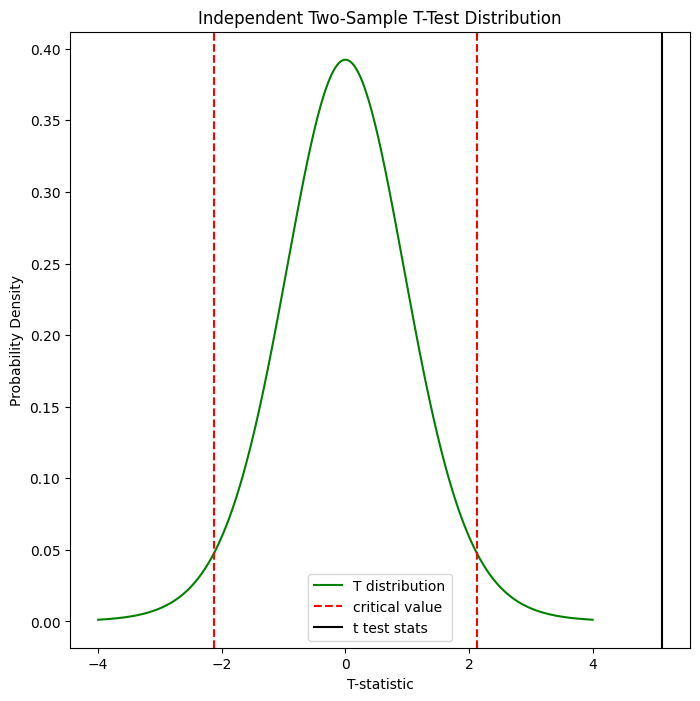

In [23]:
x = np.linspace(-4,4,1000)
y = t.pdf(x,DOF)
plt.figure(figsize=(8,8))
plt.plot(x,y,label="T distribution",color = "green")
plt.axvline(critical_value,linestyle = "--",color = "Red",label = "critical value ")
plt.axvline(-critical_value,color="Red",linestyle = "--")
plt.axvline(t_test_stat,color="black",linestyle = "solid",label = "t test stats")
plt.xlabel("T-statistic")
plt.ylabel("Probability Density")
plt.title("Independent Two-Sample T-Test Distribution")
plt.legend()
plt.show()
